## Time-Conditioned Courier Path and Order Coverage (Flag 1)

### Dataset Overview
The main table contains 72 delivery orders across three time periods for one courier-day. Receipt and destination coordinates are derived from timestamped points on supporting GPS trajectory fragments in a shared case coordinate frame. The trajectory_segment field identifies each contiguous observed fragment; gaps between fragments are not drawn as movement.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze the spatial and temporal patterns of courier delivery activity in the selected delivery area.

Role: Last-mile delivery operations analyst


Category: Courier and Order Insight

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "orders.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do the GPS path and the spatial distribution of receipt and destination locations differ across midday, evening, and late evening?

#### Analysis action

Compare the point concentration and route coverage using the same map extent across the three periods.

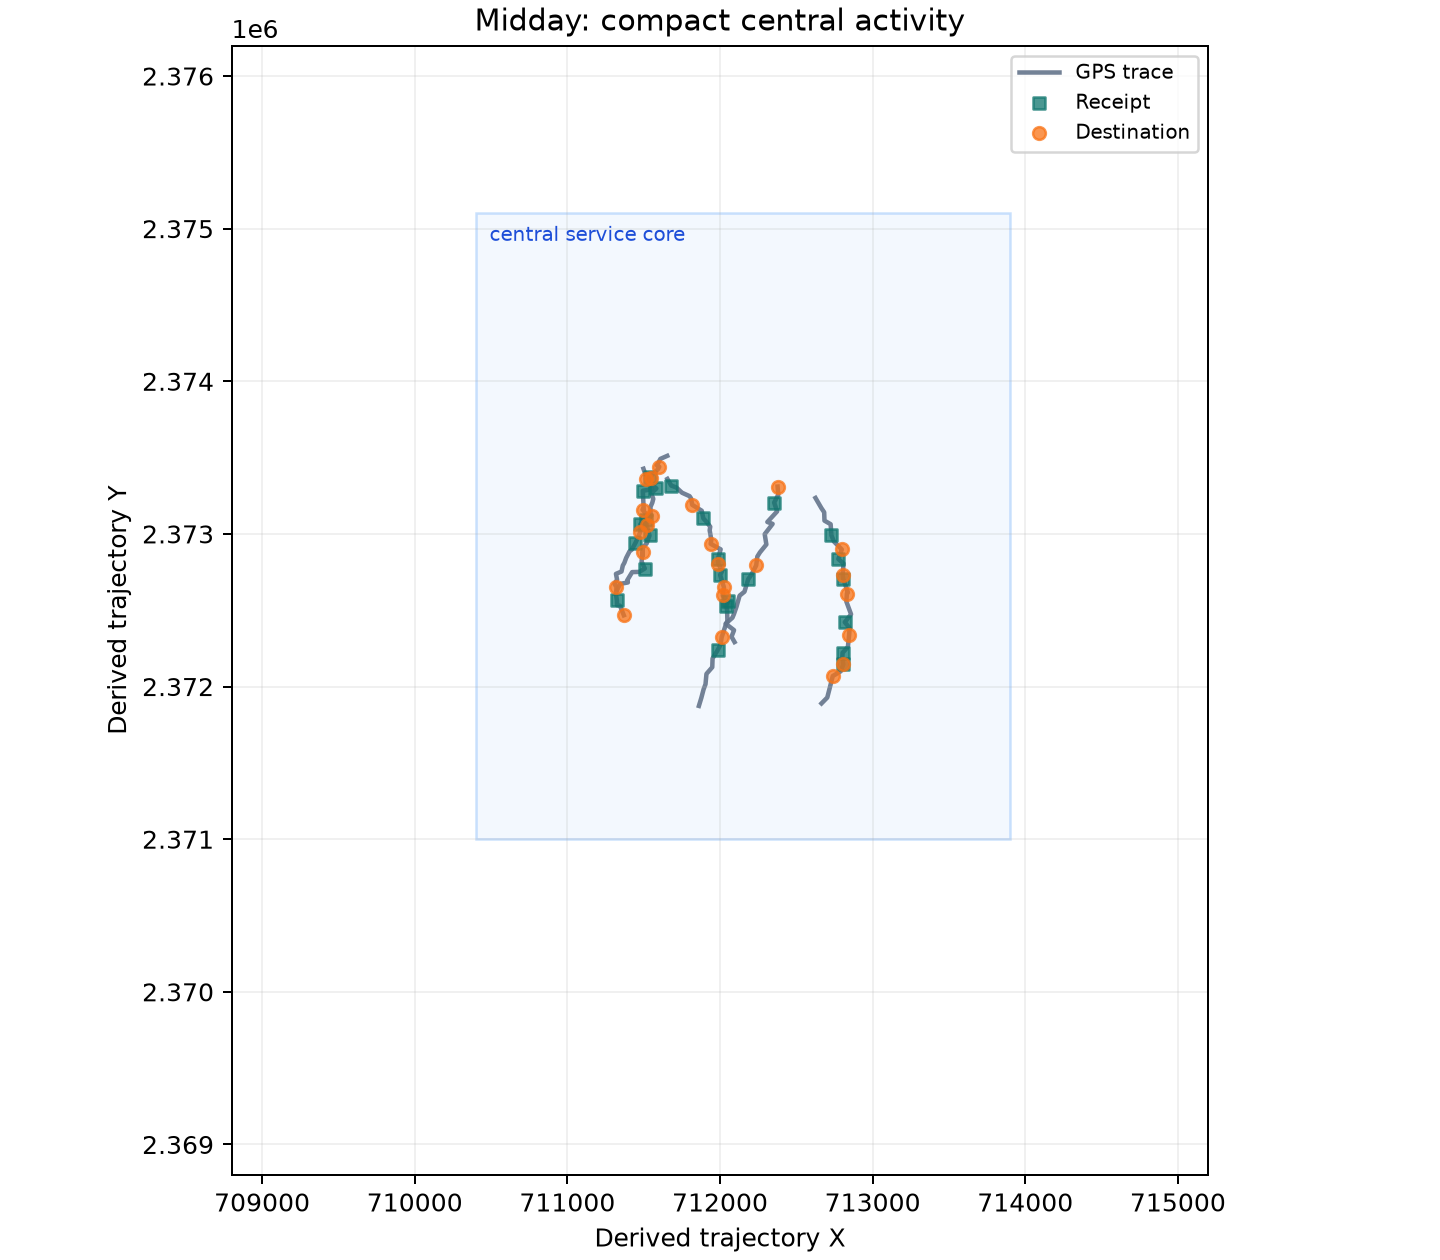

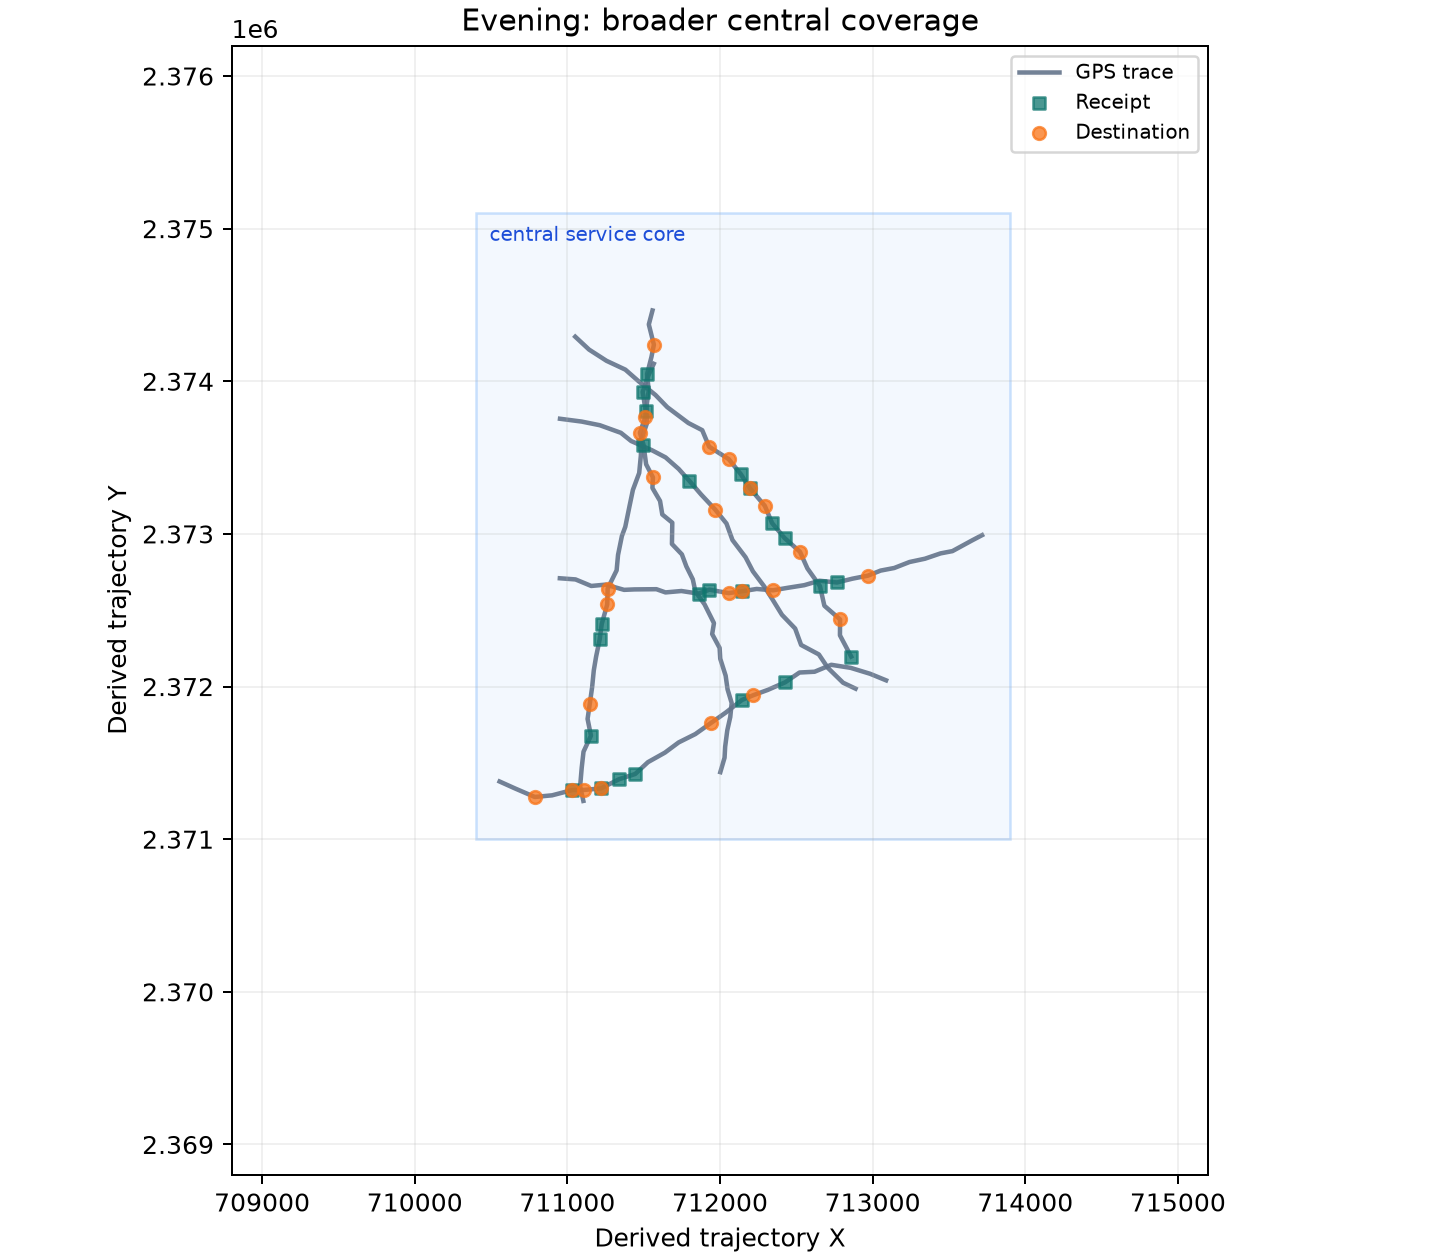

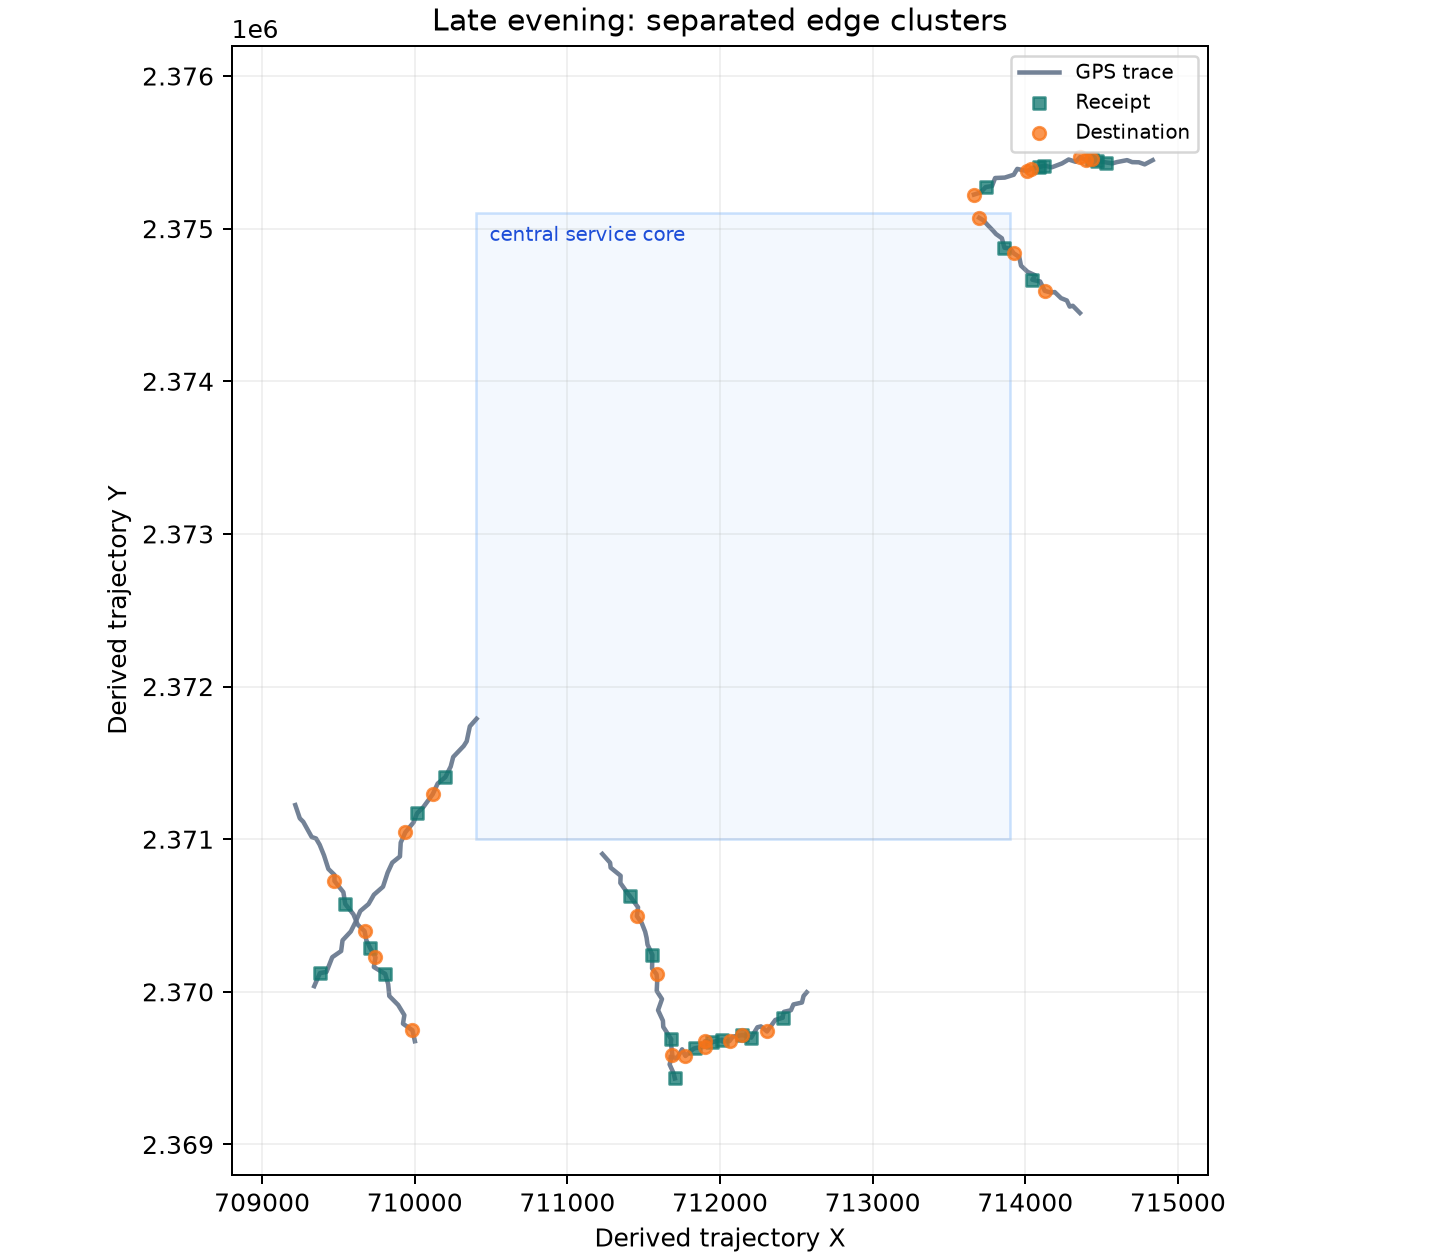

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d = df.copy(); t = user_df.copy()
d['period'] = d['receipt_time'].str.extract(r'(\d+):')[0].astype(int).map(lambda h: 'midday' if 11 <= h < 15 else ('evening' if 17 <= h < 20 else 'late_evening'))
t['period'] = t['gps_time'].str.extract(r'(\d+):')[0].astype(int).map(lambda h: 'midday' if 11 <= h < 15 else ('evening' if 17 <= h < 20 else 'late_evening'))
fig, axes = plt.subplots(1,3,figsize=(18,6), sharex=True, sharey=True)
for ax, period in zip(axes,['midday','evening','late_evening']):
 q=d[d.period==period]; tr=t[t.period==period]
 for _, s in tr.groupby('trajectory_segment'): ax.plot(s.lng,s.lat,color='gray')
 ax.scatter(q.receipt_lng,q.receipt_lat,marker='s',c='teal'); ax.scatter(q.poi_lng,q.poi_lat,c='darkorange'); ax.set_title(period); ax.set_aspect('equal')
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/time_band_maps/midday.png"))
display(Image(filename="visualizations/time_band_maps/evening.png"))
display(Image(filename="visualizations/time_band_maps/late_evening.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatial_temporal_comparison",
  "insight": "During midday, receipt and destination activity is tightly concentrated inside the central service core, unlike the wider evening and late-evening patterns.",
  "insight_value": {
    "orders_per_period": 24,
    "midday_pattern": "compact central cluster"
  },
  "plot": {
    "plot_type": "three_map_comparison",
    "title": "Courier Paths and Order Locations across Three Time Periods",
    "files": [
      "visualizations/time_band_maps/midday.png",
      "visualizations/time_band_maps/evening.png",
      "visualizations/time_band_maps/late_evening.png"
    ],
    "description": "All three maps use the same coordinate extent and show the GPS path, receipt points, destination points, and the shaded central service core."
  },
  "question": "How do the GPS path and the spatial distribution of receipt and destination locations differ across midday, evening, and late evening?",
  "actionable_insight": "Compare the point concentration and route coverage using the same map extent across the three periods.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd = df.copy(); t = user_df.copy()\nd['period'] = d['receipt_time'].str.extract(r'(\\d+):')[0].astype(int).map(lambda h: 'midday' if 11 <= h < 15 else ('evening' if 17 <= h < 20 else 'late_evening'))\nt['period'] = t['gps_time'].str.extract(r'(\\d+):')[0].astype(int).map(lambda h: 'midday' if 11 <= h < 15 else ('evening' if 17 <= h < 20 else 'late_evening'))\nfig, axes = plt.subplots(1,3,figsize=(18,6), sharex=True, sharey=True)\nfor ax, period in zip(axes,['midday','evening','late_evening']):\n q=d[d.period==period]; tr=t[t.period==period]\n for _, s in tr.groupby('trajectory_segment'): ax.plot(s.lng,s.lat,color='gray')\n ax.scatter(q.receipt_lng,q.receipt_lat,marker='s',c='teal'); ax.scatter(q.poi_lng,q.poi_lat,c='darkorange'); ax.set_title(period); ax.set_aspect('equal')\nplt.show()",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "receipt_time",
    "receipt_position",
    "destination_position",
    "task_id",
    "gps_time",
    "gps_position"
  ]
}

### **Question 2**: How does the spatial coverage of the courier path, receipt points, and destination points change from midday to evening?

#### Analysis action

Compare the two panels with their shared coordinate frame rather than comparing separately cropped maps.

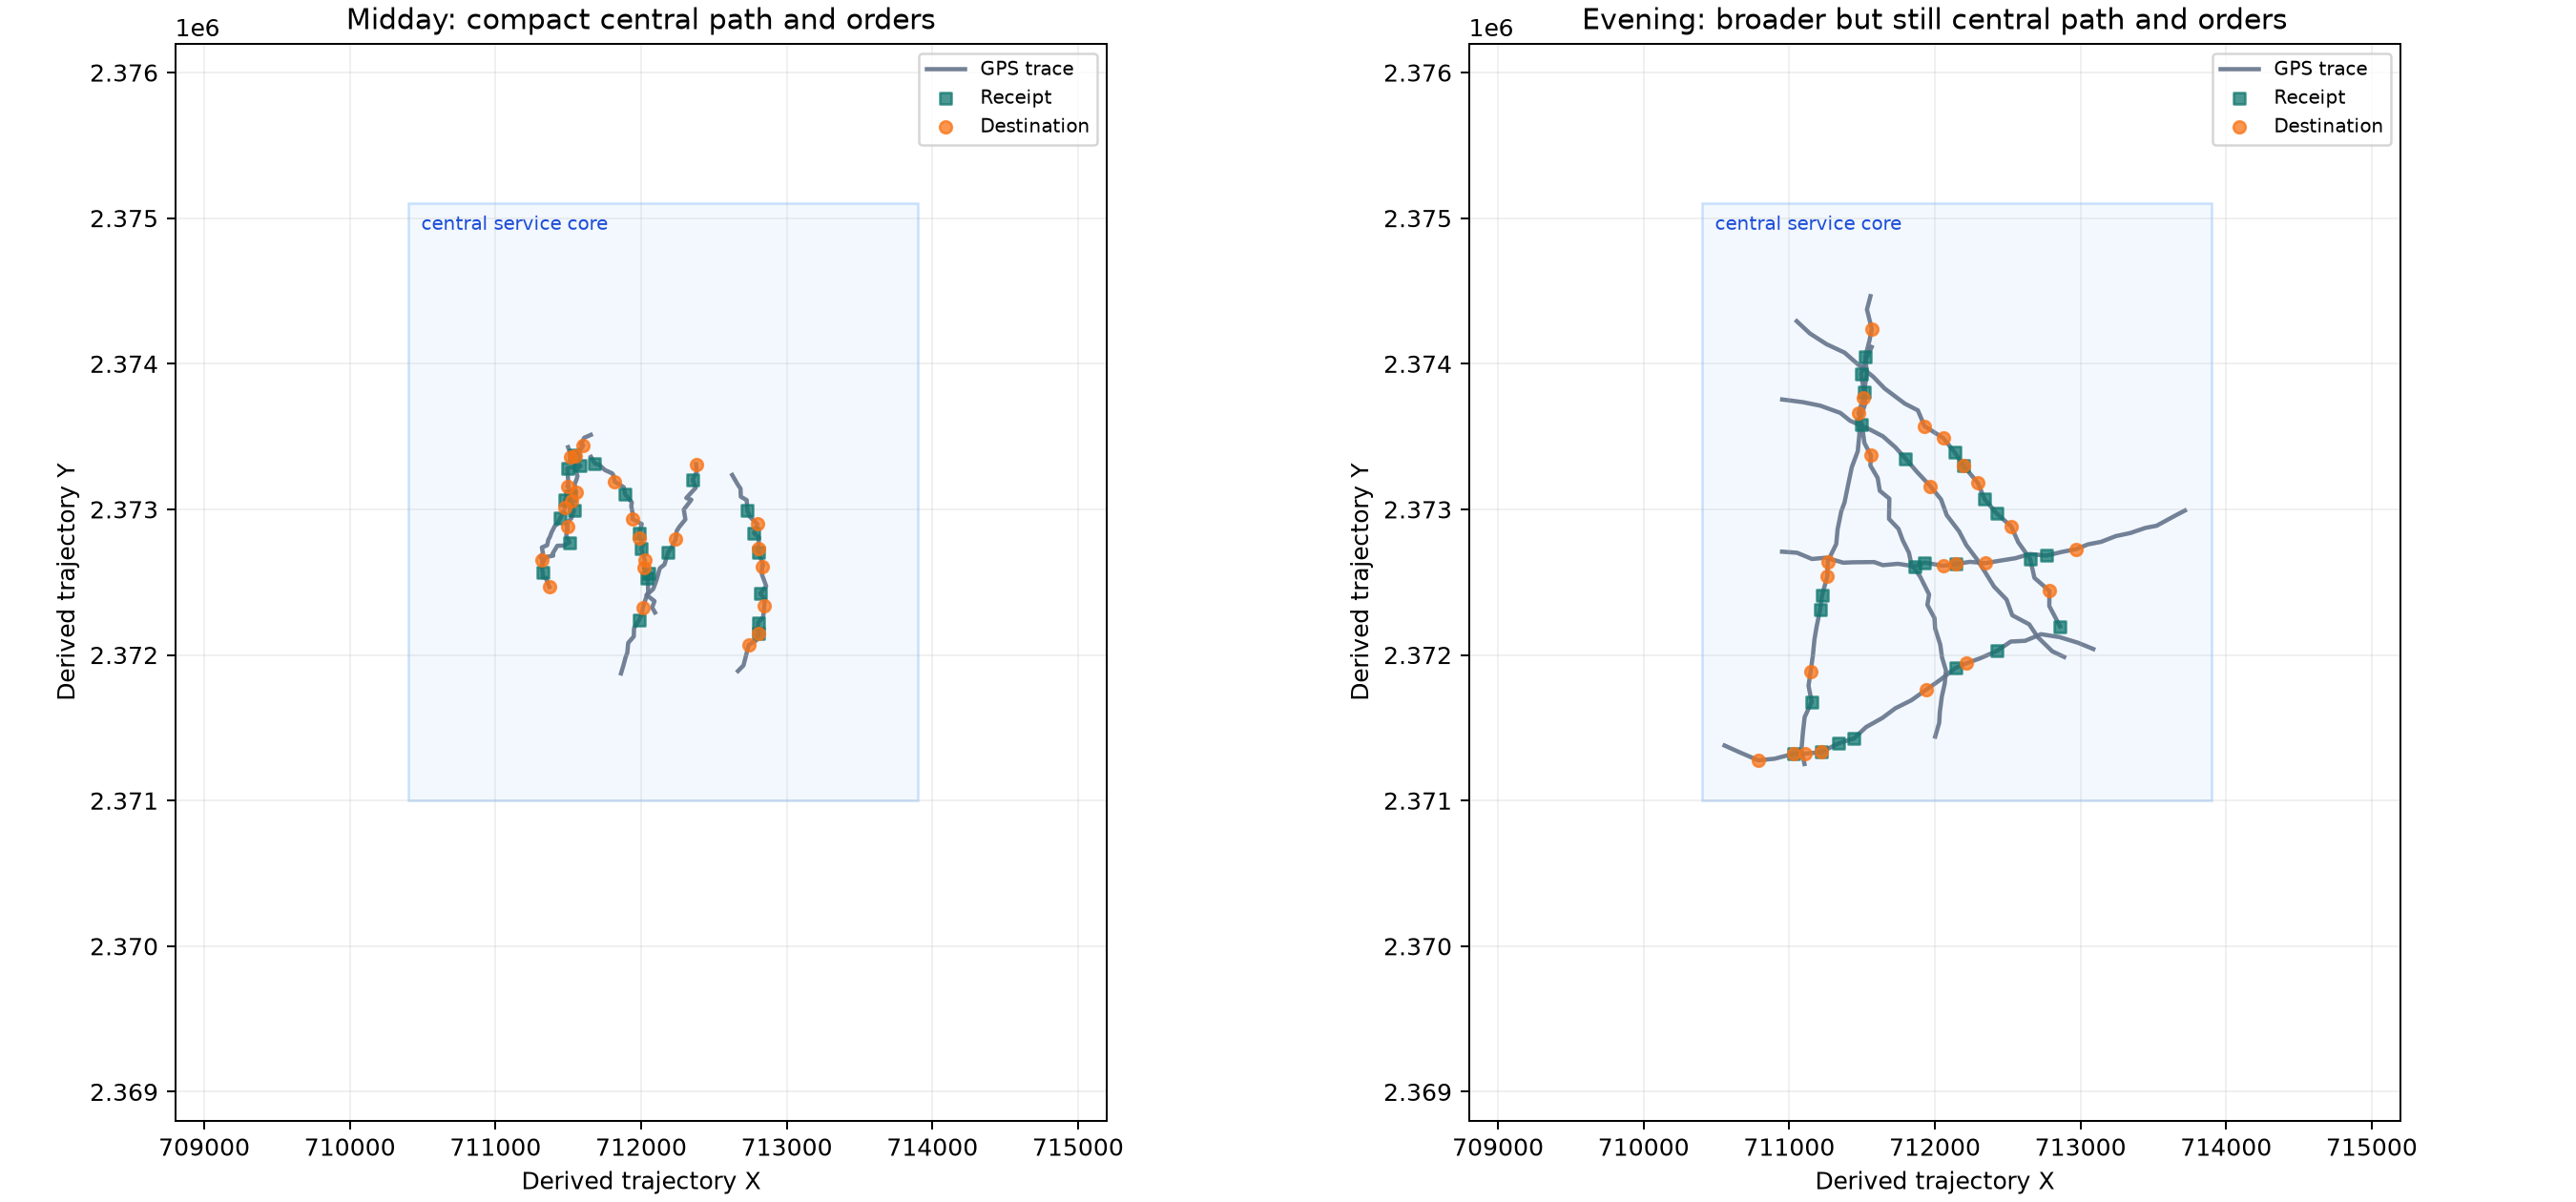

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df.copy(); t=user_df.copy()
d['period']=d['receipt_time'].str.extract(r'(\d+):')[0].astype(int).map(lambda h:'midday' if 11<=h<15 else ('evening' if 17<=h<20 else 'late_evening'))
t['period']=t['gps_time'].str.extract(r'(\d+):')[0].astype(int).map(lambda h:'midday' if 11<=h<15 else ('evening' if 17<=h<20 else 'late_evening'))
fig,axes=plt.subplots(1,2,figsize=(14,6),sharex=True,sharey=True)
for ax,period in zip(axes,['midday','evening']):
 q=d[d.period==period]; tr=t[t.period==period]
 for _, s in tr.groupby('trajectory_segment'): ax.plot(s.lng,s.lat,color='gray')
 ax.scatter(q.receipt_lng,q.receipt_lat,marker='s',c='teal',label='Receipt'); ax.scatter(q.poi_lng,q.poi_lat,c='darkorange',label='Destination'); ax.set_title(period); ax.set_aspect('equal'); ax.legend()
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/time_band_maps/midday_evening_path_order_comparison.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatial_temporal_comparison",
  "insight": "During the evening period, both the courier path and order locations cover a wider part of the central service area than at midday.",
  "insight_value": {
    "comparison": "evening spatial coverage exceeds midday while remaining within the central service core"
  },
  "plot": {
    "plot_type": "two_period_path_and_event_maps",
    "title": "Courier Paths and Order Locations: Midday versus Evening",
    "file": "visualizations/time_band_maps/midday_evening_path_order_comparison.png",
    "description": "The two panels use identical axes and the same GPS-derived order points. Every receipt and destination marker lies on its period's observed path."
  },
  "question": "How does the spatial coverage of the courier path, receipt points, and destination points change from midday to evening?",
  "actionable_insight": "Compare the two panels with their shared coordinate frame rather than comparing separately cropped maps.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df.copy(); t=user_df.copy()\nd['period']=d['receipt_time'].str.extract(r'(\\d+):')[0].astype(int).map(lambda h:'midday' if 11<=h<15 else ('evening' if 17<=h<20 else 'late_evening'))\nt['period']=t['gps_time'].str.extract(r'(\\d+):')[0].astype(int).map(lambda h:'midday' if 11<=h<15 else ('evening' if 17<=h<20 else 'late_evening'))\nfig,axes=plt.subplots(1,2,figsize=(14,6),sharex=True,sharey=True)\nfor ax,period in zip(axes,['midday','evening']):\n q=d[d.period==period]; tr=t[t.period==period]\n for _, s in tr.groupby('trajectory_segment'): ax.plot(s.lng,s.lat,color='gray')\n ax.scatter(q.receipt_lng,q.receipt_lat,marker='s',c='teal',label='Receipt'); ax.scatter(q.poi_lng,q.poi_lat,c='darkorange',label='Destination'); ax.set_title(period); ax.set_aspect('equal'); ax.legend()\nplt.show()",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "receipt_time",
    "receipt_position",
    "destination_position",
    "gps_time",
    "gps_position",
    "task_id"
  ]
}

### **Question 3**: How does the distribution of receipt and destination event dispersion compare across midday, evening, and late evening?

#### Analysis action

Compare the full event-spread distributions across periods rather than relying on a single late-evening map.

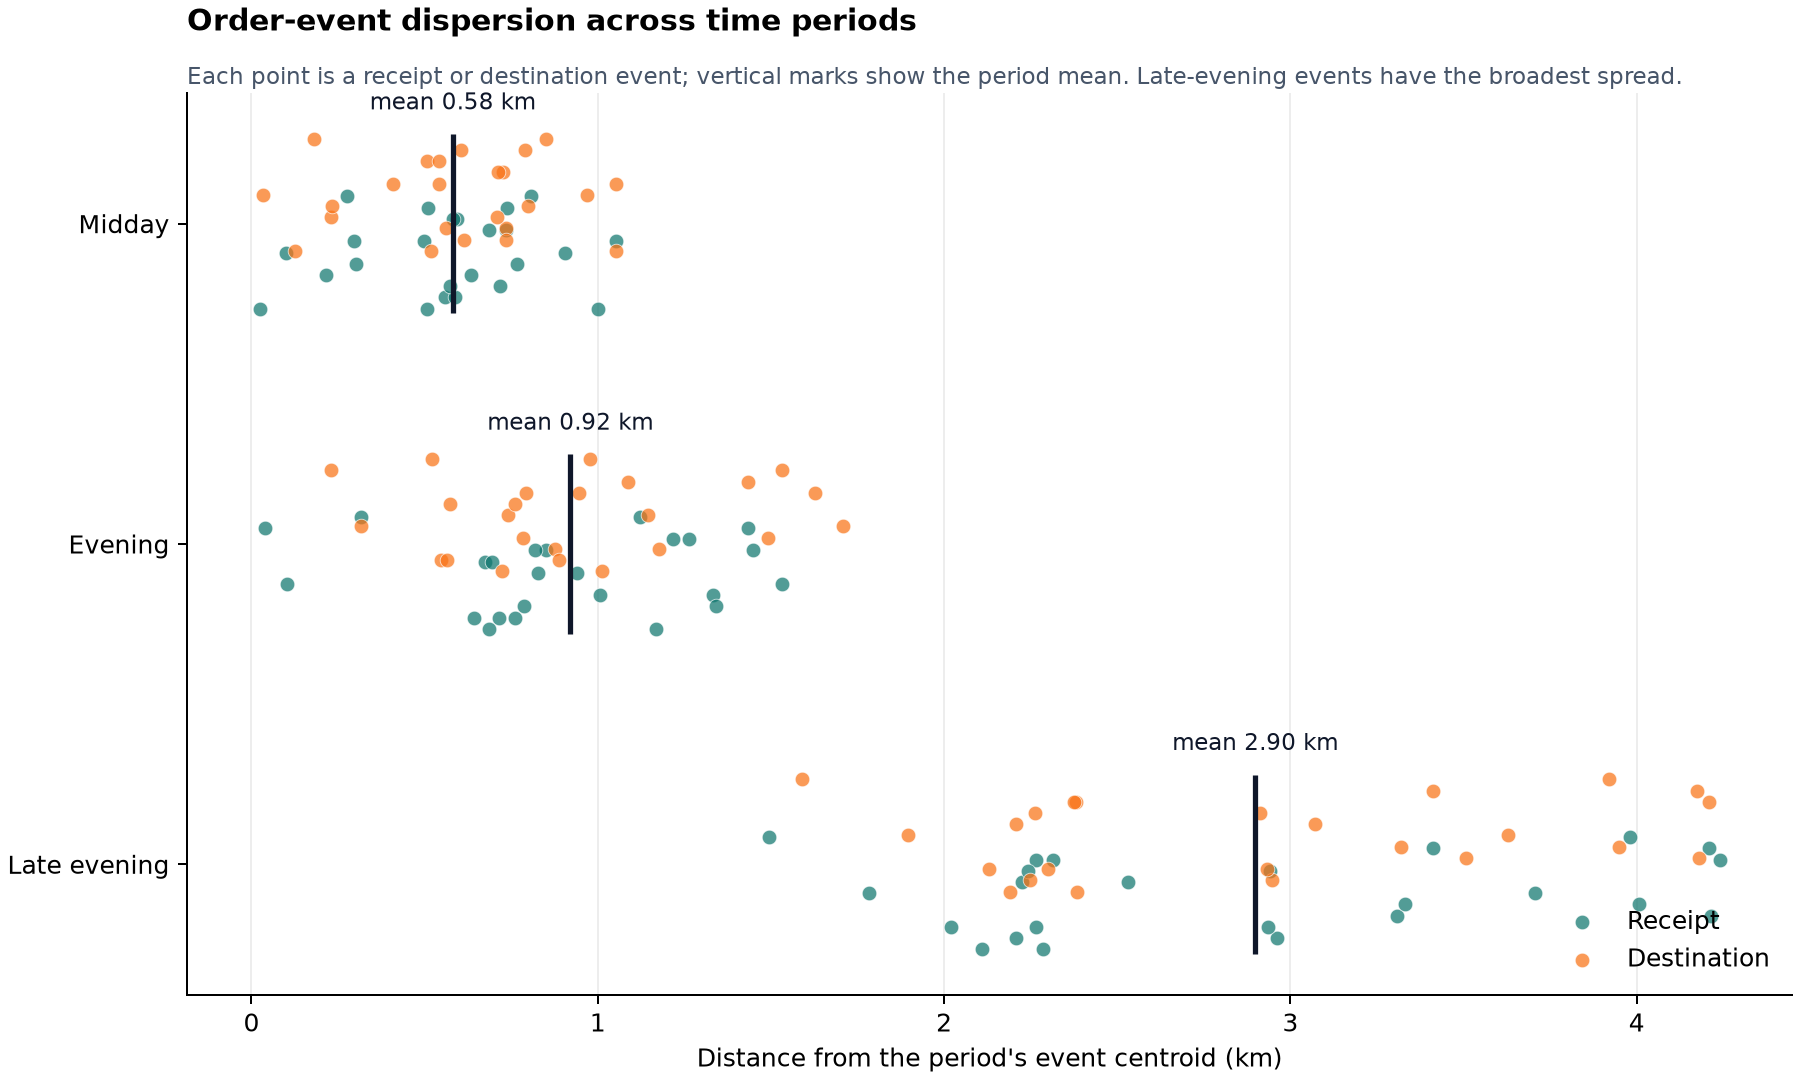

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df.copy(); d['period']=d['receipt_time'].str.extract(r'(\d+):')[0].astype(int).map(lambda h:'midday' if 11<=h<15 else ('evening' if 17<=h<20 else 'late_evening'))
events=pd.concat([d[['period','receipt_lng','receipt_lat']].rename(columns={'receipt_lng':'lng','receipt_lat':'lat'}),d[['period','poi_lng','poi_lat']].rename(columns={'poi_lng':'lng','poi_lat':'lat'})])
centres=events.groupby('period')[['lng','lat']].mean(); events=events.join(centres,on='period',rsuffix='_centre'); events['distance_km']=((events.lng-events.lng_centre)**2+(events.lat-events.lat_centre)**2)**.5/1000
for period,g in events.groupby('period'): plt.scatter(g.distance_km,[period]*len(g),alpha=.55,label=period)
plt.xlabel('distance from period centroid (km)'); plt.legend(); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/time_band_maps/event_dispersion_by_period.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatial_temporal_comparison",
  "insight": "During late evening, receipt and destination locations spread across multiple separated edge clusters rather than a single central cluster.",
  "insight_value": {
    "late_evening_orders": 24,
    "spatial_pattern": "multiple separated edge clusters",
    "comparison": "late-evening event spread exceeds the midday and evening distributions"
  },
  "plot": {
    "plot_type": "event_dispersion_dot_distribution",
    "title": "Order-Event Dispersion across Time Periods",
    "file": "visualizations/time_band_maps/event_dispersion_by_period.png",
    "description": "A non-map dot distribution compares each receipt and destination event's distance from its period centroid across midday, evening, and late evening."
  },
  "question": "How does the distribution of receipt and destination event dispersion compare across midday, evening, and late evening?",
  "actionable_insight": "Compare the full event-spread distributions across periods rather than relying on a single late-evening map.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df.copy(); d['period']=d['receipt_time'].str.extract(r'(\\d+):')[0].astype(int).map(lambda h:'midday' if 11<=h<15 else ('evening' if 17<=h<20 else 'late_evening'))\nevents=pd.concat([d[['period','receipt_lng','receipt_lat']].rename(columns={'receipt_lng':'lng','receipt_lat':'lat'}),d[['period','poi_lng','poi_lat']].rename(columns={'poi_lng':'lng','poi_lat':'lat'})])\ncentres=events.groupby('period')[['lng','lat']].mean(); events=events.join(centres,on='period',rsuffix='_centre'); events['distance_km']=((events.lng-events.lng_centre)**2+(events.lat-events.lat_centre)**2)**.5/1000\nfor period,g in events.groupby('period'): plt.scatter(g.distance_km,[period]*len(g),alpha=.55,label=period)\nplt.xlabel('distance from period centroid (km)'); plt.legend(); plt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "receipt_time",
    "receipt_position",
    "destination_position",
    "task_id"
  ]
}

### Summary of Findings (Flag 1)

Across one observed courier-day, midday activity is compact and concentrated in the central service core. Evening activity covers a wider portion of that same central service area. Late-evening activity is distributed across several separated edge clusters. In every view, receipt and destination coordinates are sampled from the GPS path of their corresponding period.